In [1]:
LANG = "en"

# J-space readouts under weight quantization — walkthrough

**Question:** Does the global-workspace signal that Anthropic's Jacobian lens reads from a language
model's intermediate layers survive quantization?

This notebook walks through the method and shows the results. It runs on the stored activations
(`results/activations/`) and result tables (`results/tables/`); the pipeline behind it is
`python -m jspace_quant capture | analyze | plot` (see `docs/en/03-setup.md`). Full write-up:
`docs/en/02-methodology.md`, `docs/en/05-results.md`.

In [2]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

from jspace_quant import analysis, capture, config, readout

pd.set_option("display.precision", 3)
T, F = config.TABLES_DIR, config.FIGURES_DIR / LANG
summary = json.loads((T / "summary.json").read_text())
band = tuple(summary["workspace_band"])

## 1. Model and quantizations

Spark-X2.6-4B (36 layers, residual width 2560, hybrid sliding-window/full attention). We only use
**flat** quants — every weight tensor has the same type — so that bit width is the only variable.

- **Main study:** BF16 (reference) → Q8_0 → Q4_0
- **Extension:** a bit-width ladder in two families (legacy: Q5_0; K-quants: Q6_K … Q2_K) and a
  component ablation (attention / MLP / embedding alone in Q4_0)

Bits per weight are measured from the GGUF files:

In [3]:
pd.read_csv(T / "models.csv")[["model", "family", "bits_per_weight", "tensor_types"]]

,model,family,bits_per_weight,tensor_types
0,bf16,ref,16.001,"{""BF16"": 217}"
1,q8_0,legacy,8.501,"{""Q8_0"": 217}"
2,q5_0,legacy,5.501,"{""Q5_0"": 217}"
3,q4_0,legacy,4.501,"{""Q4_0"": 217}"
4,q6_k,kquant,6.564,"{""Q6_K"": 217}"
5,q5_k,kquant,5.501,"{""Q5_K"": 217}"
6,q4_k,kquant,4.501,"{""Q4_K"": 217}"
7,q3_k,kquant,3.439,"{""Q3_K"": 217}"
8,q2_k,kquant,2.626,"{""Q2_K"": 217}"
9,q4_0-attn,ablation,13.357,"{""BF16"": 109, ""Q4_0"": 108}"


## 2. What the lens does

For a layer `l` and a position, take the residual-stream vector `h_l` and read it out:

```
logits = Unembed( RMSNorm( A_l · h_l + b_l ) )
```

`A_l` maps the space of layer `l` into the space of the last layer. With `A_l = I` this is the classic
**logit lens**. The paper defines `A_l` as the averaged Jacobian `E[∂h_final/∂h_l]`. llama.cpp has no
autograd, so we fit `A_l, b_l` by **ridge regression** of `h_35` on `h_l` over 1000 WikiText paragraphs
(forward passes only — a correlational surrogate in the tuned-lens family).

**Live example** on the stored activations: the French prompt "Après la nuit vient le" ("after the
night comes the") — answer "jour". The text contains the French "nuit"; the question is whether the
model internally forms the *English* concept "night", and at which layer it becomes readable.

In [4]:
acts, meta = capture.load("bf16", "evals")
i = next(k for k, it in enumerate(meta) if it["name"] == "fr-time-after-night")
item = meta[i]
print(item["prompt"].split("assistant\n")[-1], "→ target:", item["target"])
night = next(c for c in item["intermediates"] if c["word"] == "night")["token_ids"]

rows = []
for arm_name in ["bf16|identity", "bf16|bf16-A"]:
    arm = config.ARMS_BY_NAME[arm_name]
    for layer in range(0, 36, 3):
        logits = readout.arm_logits(arm, layer, acts[i, layer][None])
        rows.append({"readout": "logit lens" if arm.lens is None else "lens", "layer": layer,
                     "rank of 'night'": int(readout.min_rank(logits, night)[0])})
pd.DataFrame(rows).pivot(index="layer", columns="readout", values="rank of 'night'")

Après la nuit vient le " → target: jour


readout,lens,logit lens
layer,,
0,2633,54050
3,434,110929
6,133,70758
9,136,2504
12,134,63135
15,369,21681
18,225,4108
21,104,9431
24,9,143


With the logit lens "night" stays far back; with the fitted lens it moves into the top 10 in the
late-middle layers, before the model answers. That is the global-workspace signal.

## 3. How do we measure whether quantization changes anything?

Each **experimental arm** combines one model's activations, a lens and an unembedding:

In [5]:
pd.DataFrame([{"arm": a.name, "model": a.model, "lens": a.lens or "identity", "unembedding": a.unembed,
               "role": a.role} for a in analysis.available_arms() if a.model in config.MAIN_MODELS])

,arm,model,lens,unembedding,role
0,bf16|bf16-A,bf16,bf16-A,bf16,reference
1,bf16|bf16-B,bf16,bf16-B,bf16,noise
2,bf16|identity,bf16,identity,bf16,identity
3,q8_0|bf16-A,q8_0,bf16-A,q8_0,fixed
4,q8_0|bf16-A|U=bf16,q8_0,bf16-A,bf16,fixed_ref_unembed
5,q8_0|q8_0-A,q8_0,q8_0-A,q8_0,refit
6,q8_0|identity,q8_0,identity,q8_0,identity
7,q4_0|bf16-A,q4_0,bf16-A,q4_0,fixed
8,q4_0|bf16-A|U=bf16,q4_0,bf16-A,bf16,fixed_ref_unembed
9,q4_0|q4_0-A,q4_0,q4_0-A,q4_0,refit


- **fixed lens** (BF16 lens on the quant): did the space *stay the same*?
- **refitted** (lens fitted on the quant): is it *still linearly readable*?
- **BF16 unembedding**: separates drift in the residual stream from a less precise 4-bit readout layer.
- **noise floor**: a second BF16 lens, fitted on a different corpus only. Every quant effect must be
  clearly larger.

**Why the noise floor matters:** comparing the lens *matrices*, the two BF16 lenses differ more than the
BF16 and Q4_0 lenses. When *reading out* real activations they largely agree — the matrices are barely
determined in directions where activations don't vary. So we only measure readouts.

In [6]:
A, B, Q4 = (readout.lens(n) for n in ["bf16-A", "bf16-B", "q4_0-A"])
def rel(L1, L2, l):
    return np.linalg.norm(L1.jacobians[l] - L2.jacobians[l]) / np.linalg.norm(L1.jacobians[l])
pd.DataFrame({"layer": [0, 10, 20, 30],
              "matrix distance A↔B (corpus only)": [rel(A, B, l) for l in (0, 10, 20, 30)],
              "matrix distance A↔Q4_0 lens": [rel(A, Q4, l) for l in (0, 10, 20, 30)]})

,layer,matrix distance A↔B (corpus only),matrix distance A↔Q4_0 lens
0,0,0.956,0.484
1,10,0.925,0.608
2,20,0.778,0.571
3,30,0.351,0.257


## 4. Metrics

- **pass@k** (the paper's metric) on its six eval sets: share of hidden intermediate concepts whose best
  rank across layers is ≤ k. `association` and `poetry` are already at floor on BF16 and excluded from
  hypothesis testing; the **core** aggregate covers the other four sets.
- **Agreement with the reference per layer:** top-1 equal, top-10 overlap, KL divergence.
- **Fidelity:** does the readout predict the model's *own* output?
- **Behavior check:** answer accuracy, perplexity.
- **Statistics:** 95 % bootstrap CIs, paired against the reference, clustered by paragraph on text.

## 5. Where do the concepts become readable?

workspace band: (22, 34) | floor sets: ['association', 'poetry']


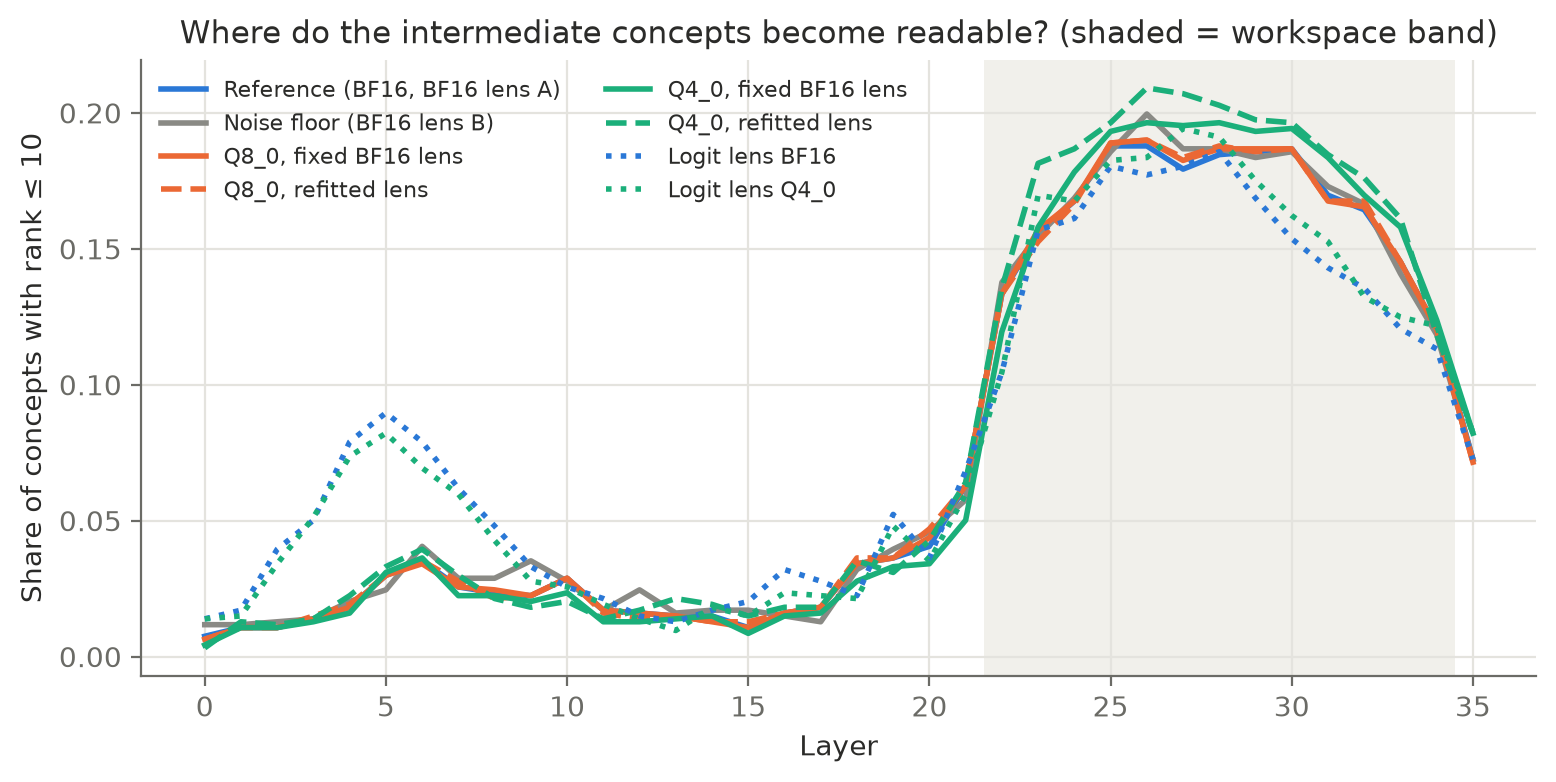

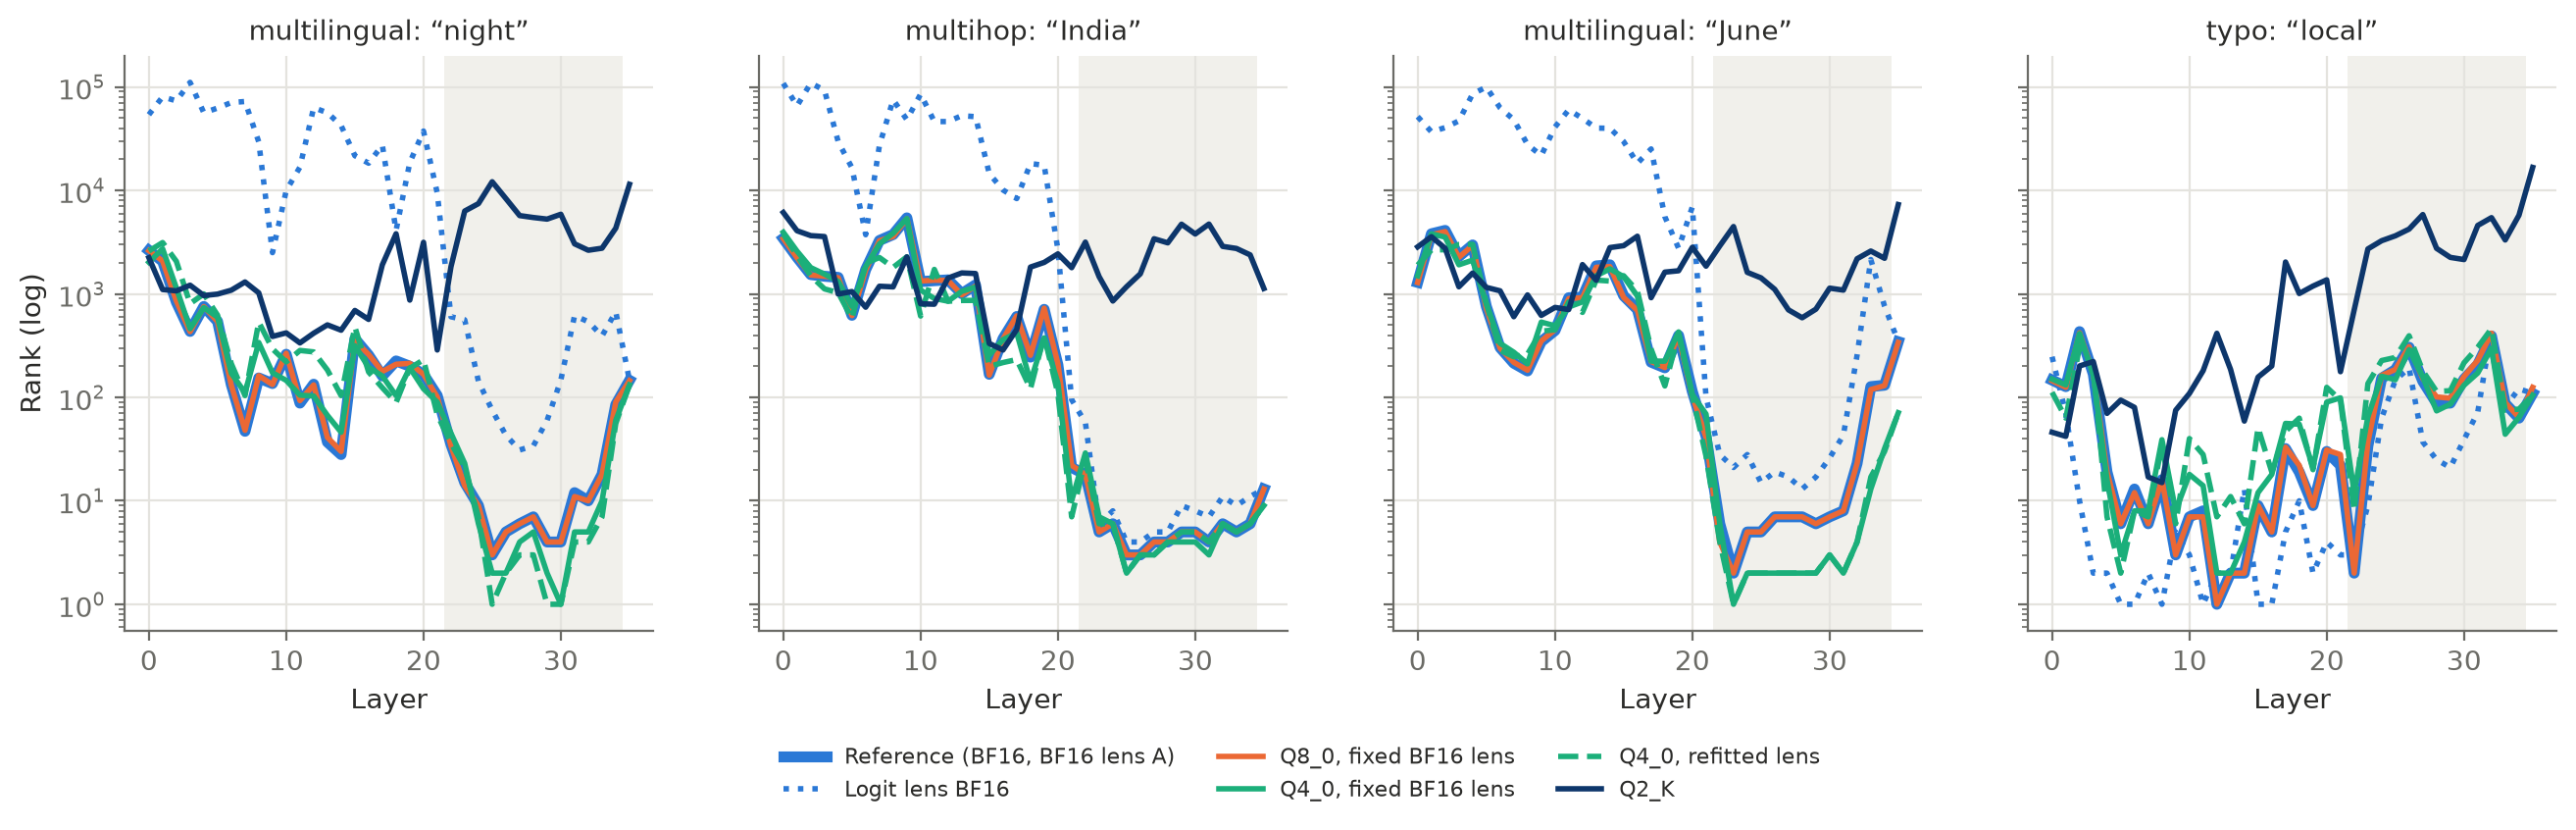

In [7]:
print("workspace band:", band, "| floor sets:", summary["floor_sets"])
display(Image(F / "hit_rate_per_layer.png", width=900))
display(Image(F / "concept_trajectories.png", width=1100))

## 6. Do the concepts survive? (pass@10, core)

In [8]:
pak = pd.read_csv(T / "pass_at_k.csv")
tab = pak[(pak.k == 10) & (pak.set == config.AGG_CORE) & (pak.scope == config.SCOPE_ALL) & (pak.role == "fixed")]
tab[["arm", "pass_at_k", "delta_ref", "delta_ci_lo", "delta_ci_hi"]].reset_index(drop=True)

,arm,pass_at_k,delta_ref,delta_ci_lo,delta_ci_hi
0,q8_0|bf16-A,0.439,0.005,-0.003,0.014
1,q4_0|bf16-A,0.416,-0.019,-0.047,0.009
2,q5_0|bf16-A,0.425,-0.009,-0.027,0.008
3,q6_k|bf16-A,0.434,0.000,-0.011,0.011
4,q5_k|bf16-A,0.412,-0.022,-0.038,-0.008
5,q4_k|bf16-A,0.439,0.005,-0.015,0.027
6,q3_k|bf16-A,0.380,-0.055,-0.089,-0.019
7,q2_k|bf16-A,0.177,-0.258,-0.306,-0.211
8,q4_0-attn|bf16-A,0.416,-0.019,-0.039,0.003
9,q4_0-ffn|bf16-A,0.425,-0.009,-0.031,0.012


## 7. The readout distribution drifts much earlier

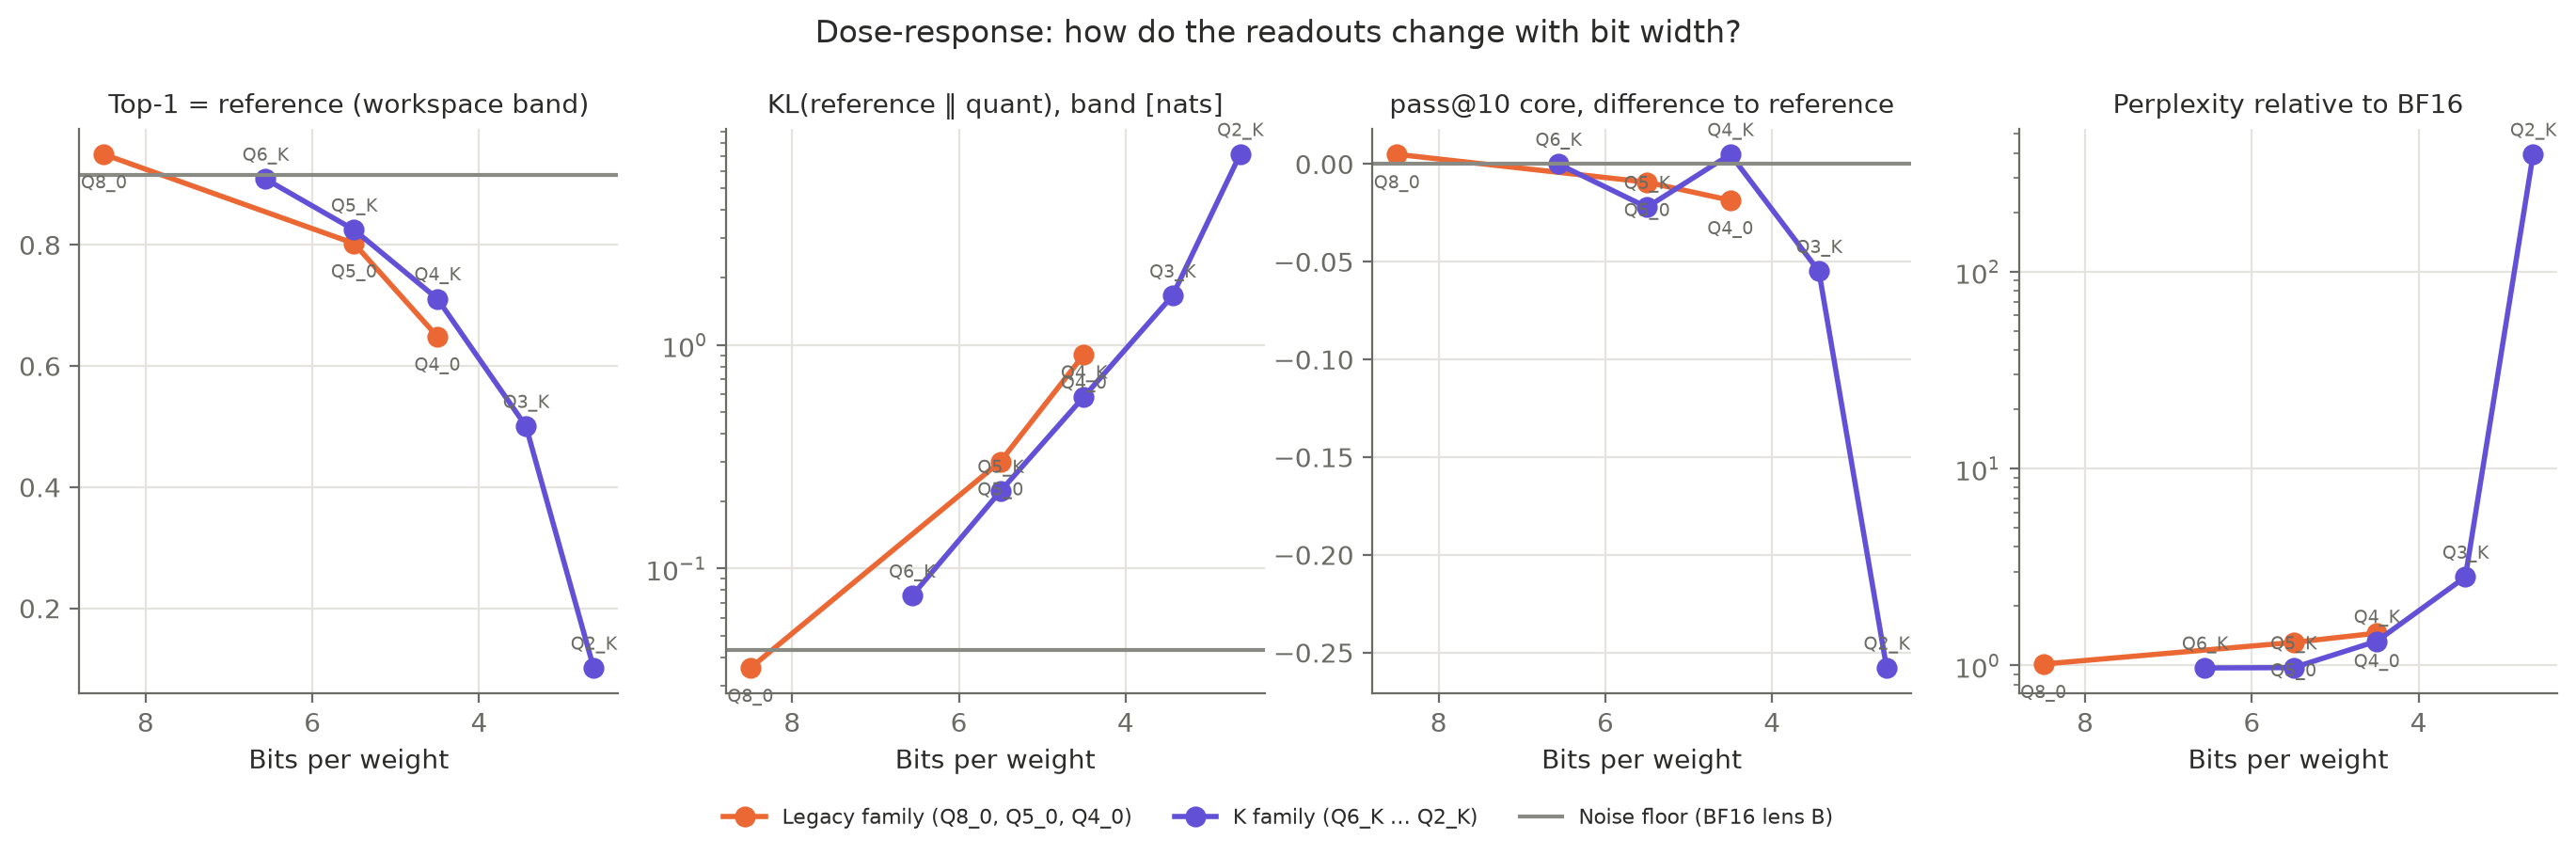

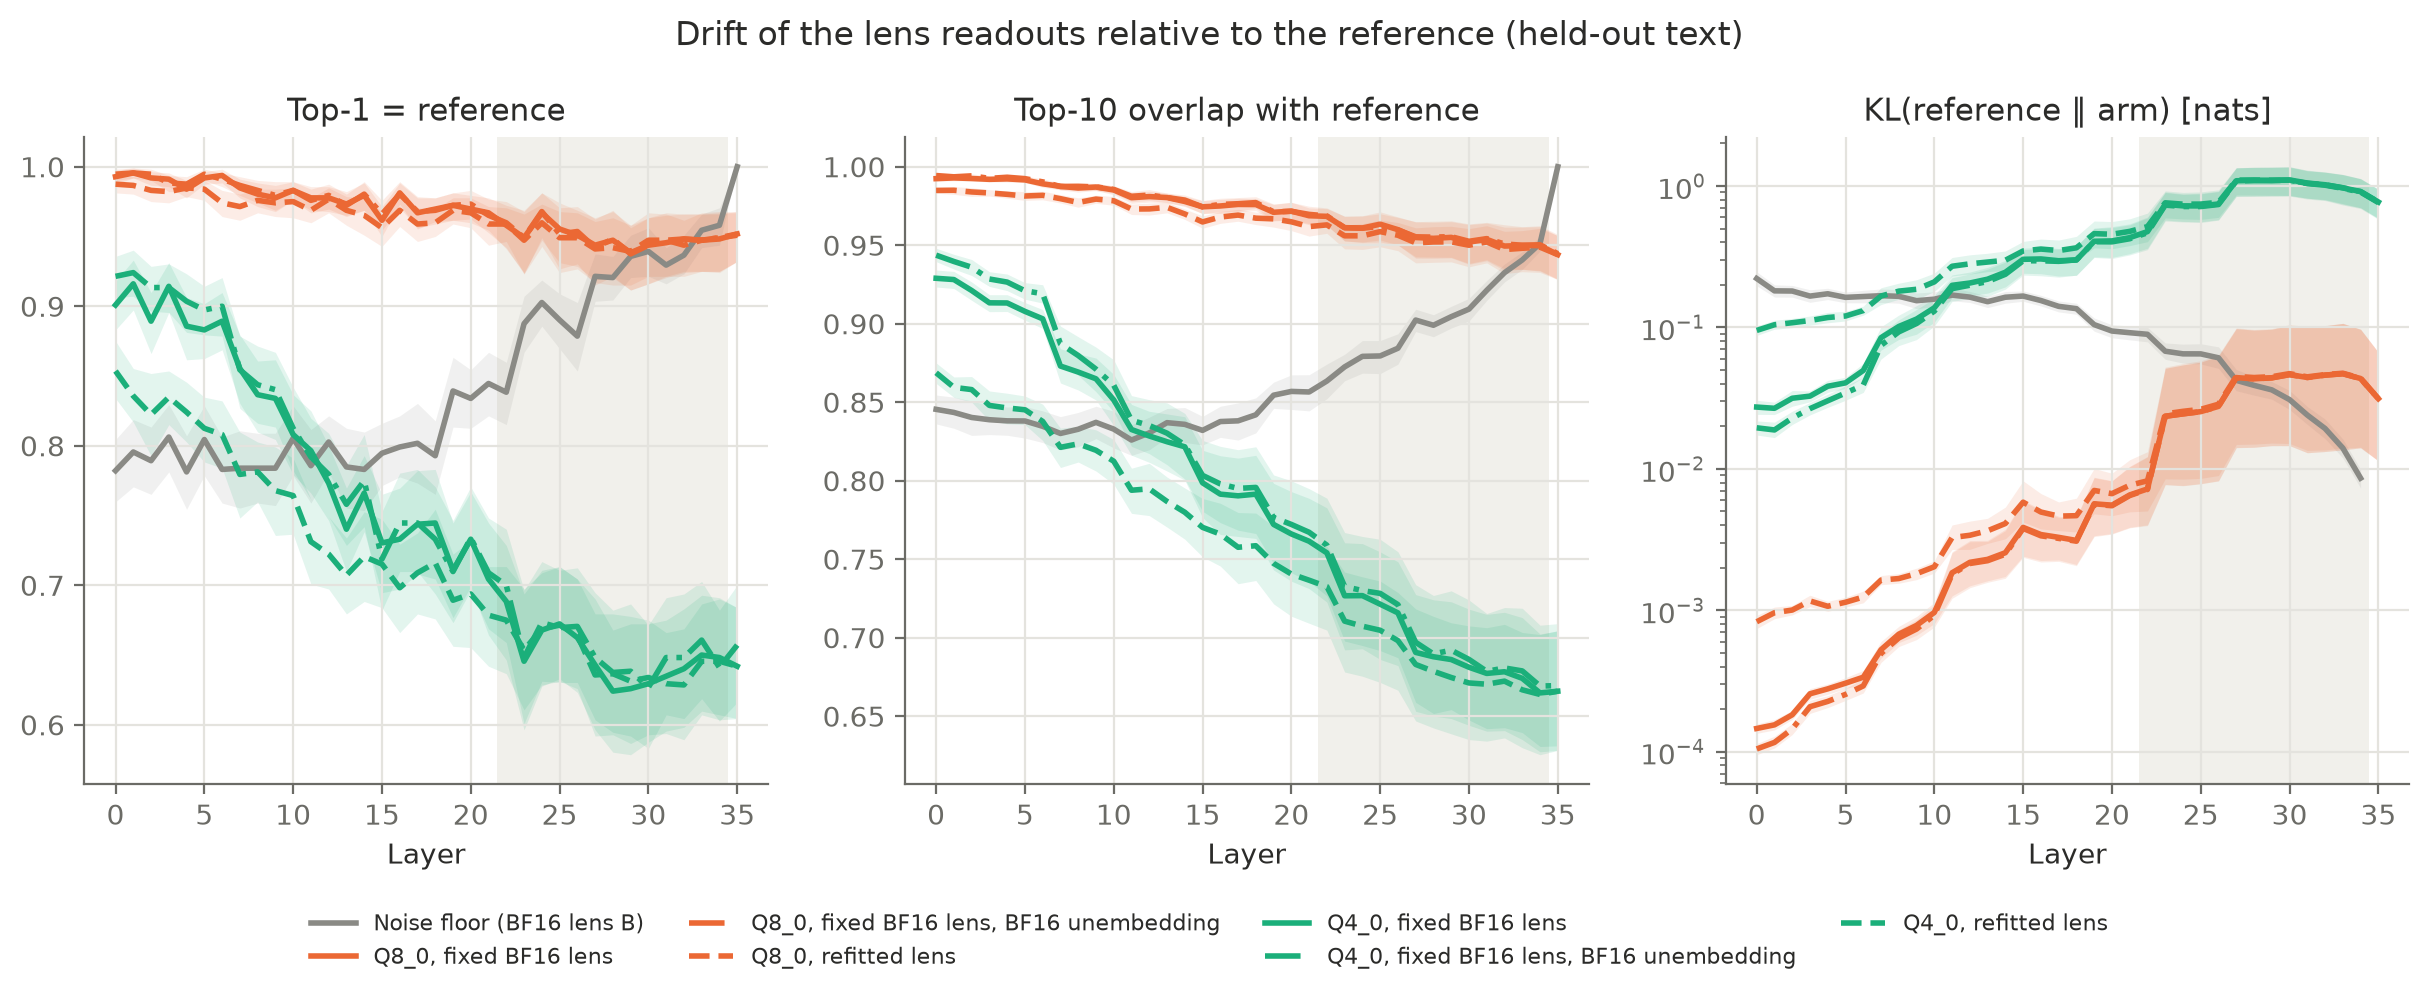

In [9]:
display(Image(F / "dose_response.png", width=1100))
display(Image(F / "agreement_per_layer_heldout.png", width=1100))

## 8. Representations without a lens, per layer

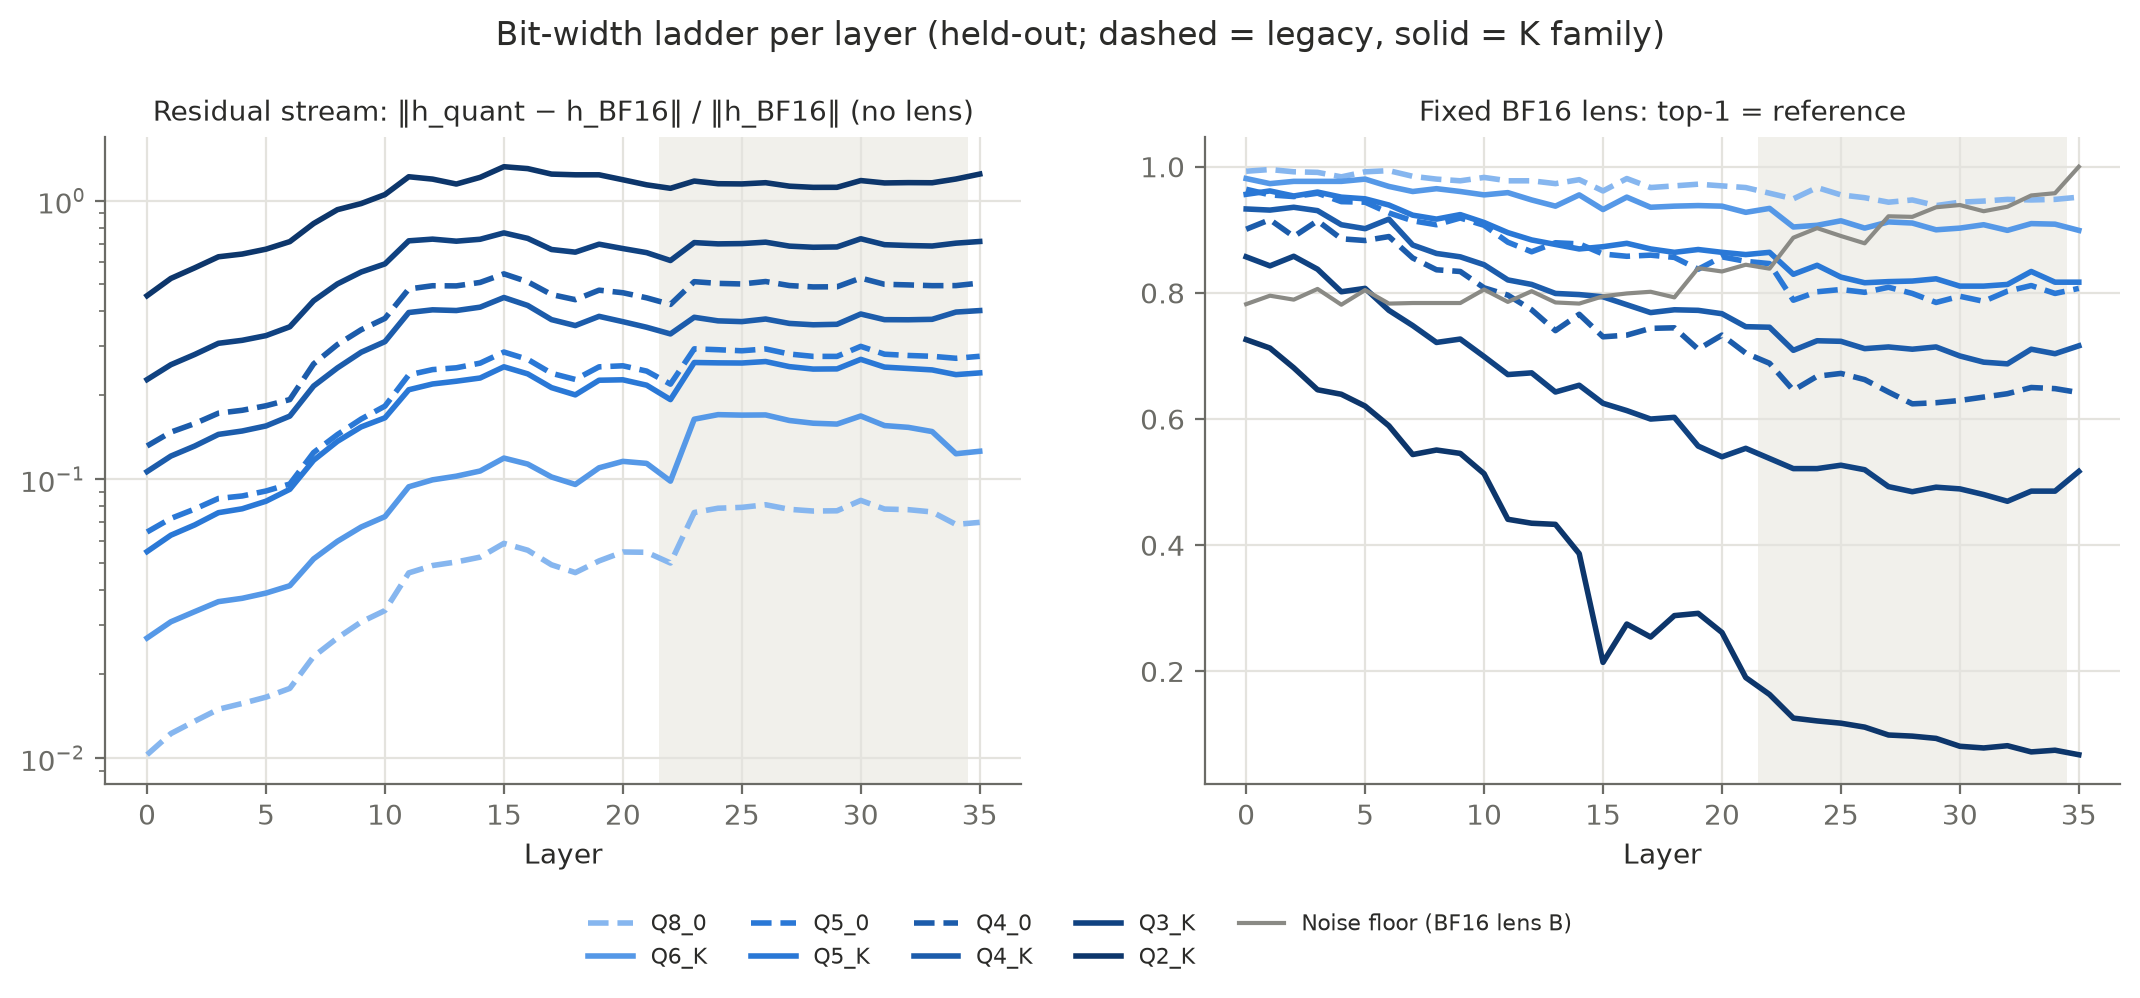

In [10]:
display(Image(F / "ladder_per_layer.png", width=1100))

## 9. Which component causes the drift?

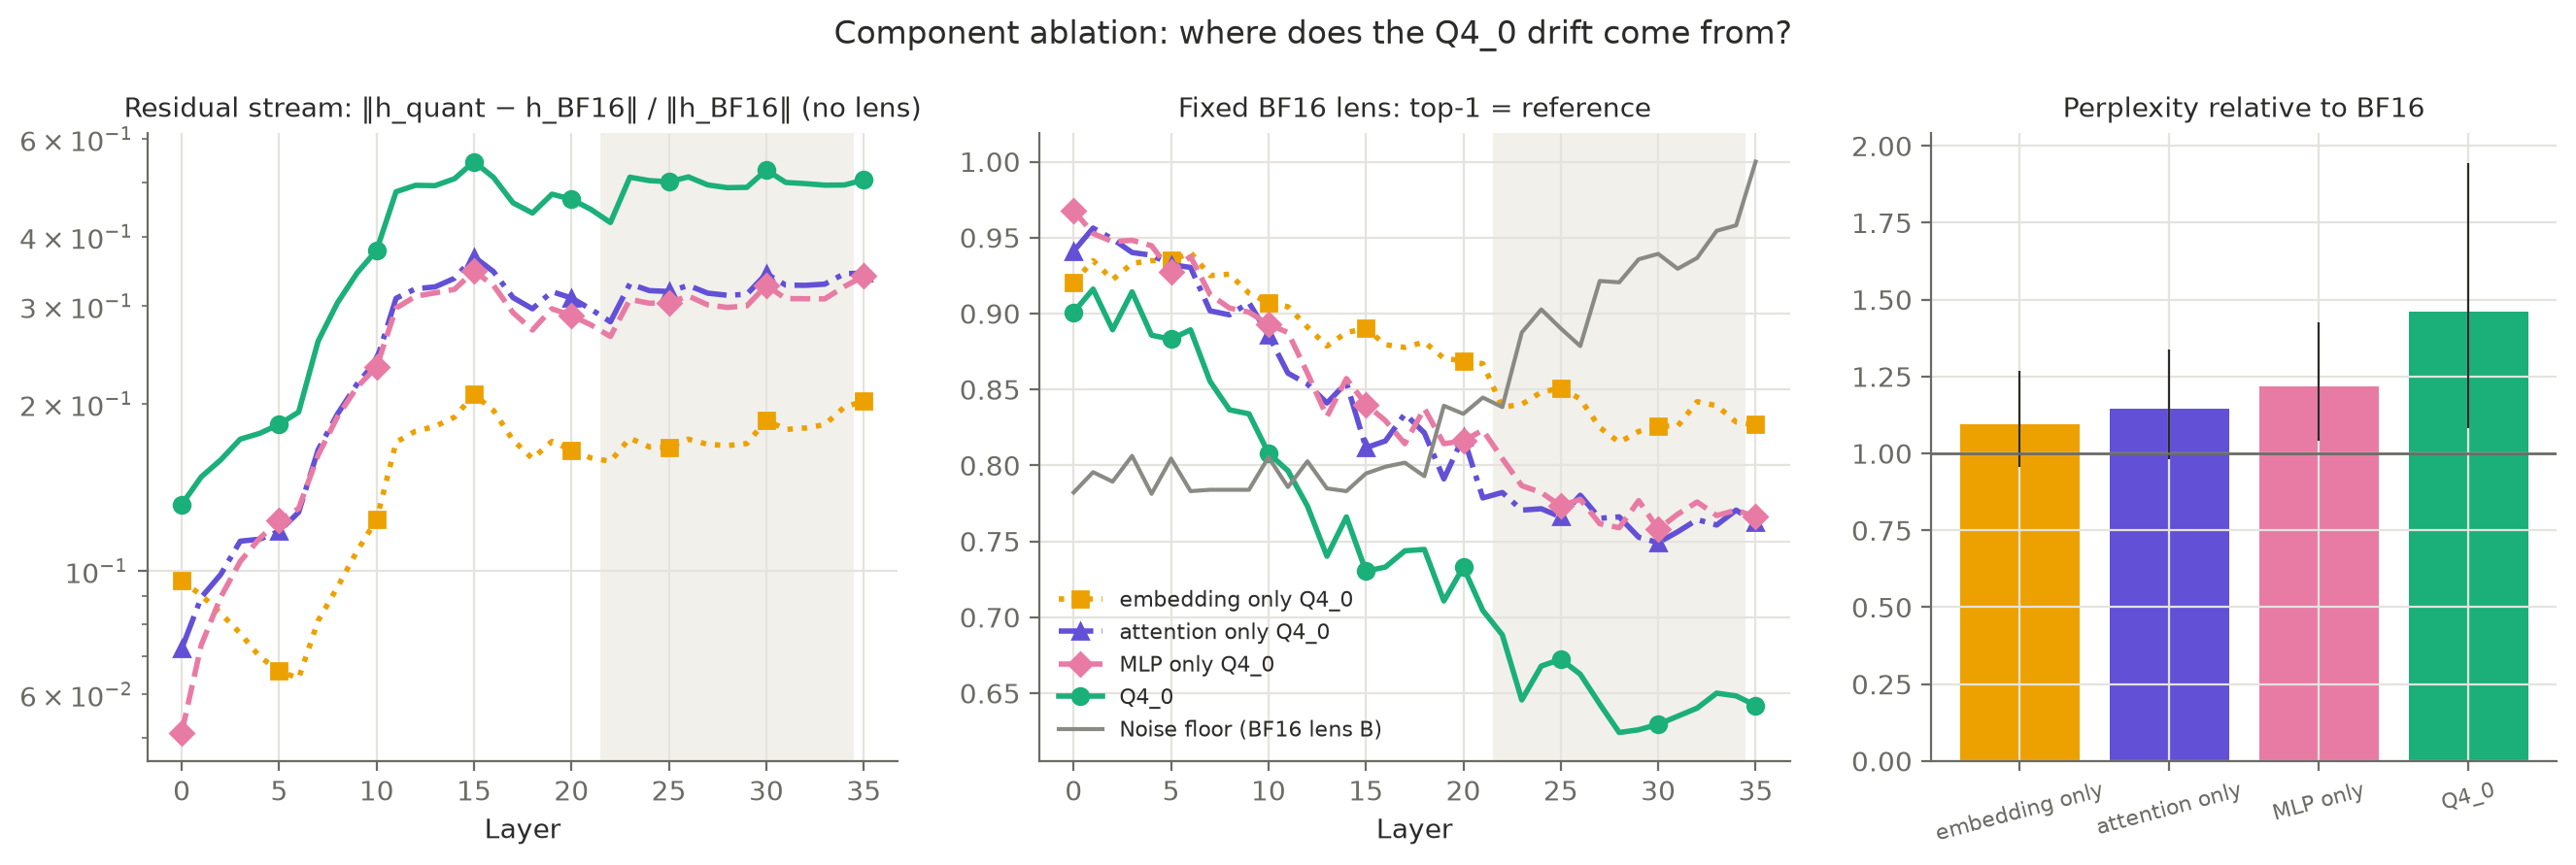

In [11]:
display(Image(F / "ablation.png", width=1100))

## 10. Which concepts suffer?

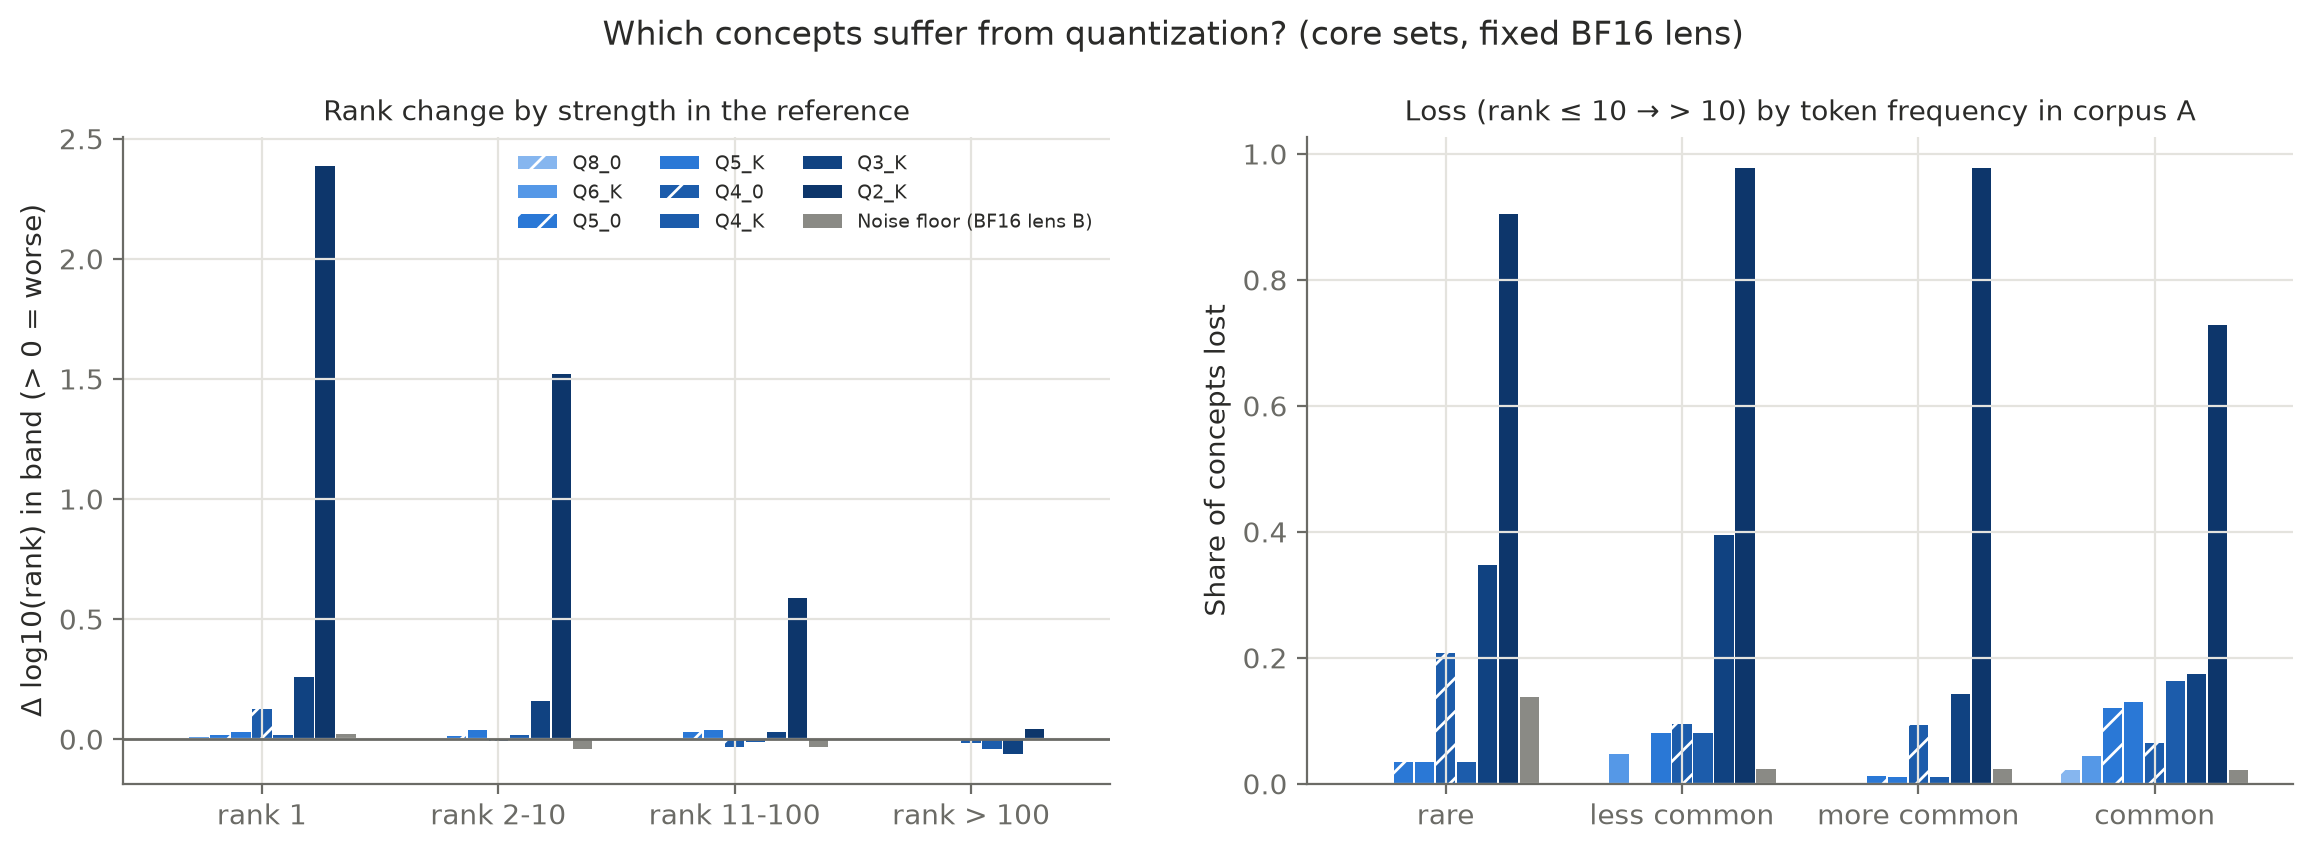

In [12]:
display(Image(F / "concept_loss.png", width=1100))

## 11. Causal test: do lens directions still steer the model?

On the paper's `probe-swap` set (e.g. "the language spoken in the country where the Amazon River ends
is" → Brazil → Portuguese) we steer the residual stream at L18–L25 away from the bridge concept and
towards a swap concept (Mexico) and check whether the answer follows (Spanish).

,model,lens,baseline_accuracy,steer_success,steer_success_vs_ref,steer_success_vs_ref_ci_lo,steer_success_vs_ref_ci_hi,steer_control,ablate_drop
0,bf16,bf16-A,0.395,0.267,0.000,0.000,0.000,0.047,0.047
1,bf16,bf16-B,0.395,0.256,-0.012,-0.058,0.035,0.058,0.058
2,q2_k,bf16-A,0.012,0.012,-0.256,-0.349,-0.163,0.000,0.000
3,q3_k,bf16-A,0.221,0.151,-0.116,-0.198,-0.047,0.035,0.058
4,q4_0,bf16-A,0.384,0.233,-0.035,-0.116,0.035,0.058,0.047
5,q4_0,q4_0-A,0.384,0.209,-0.058,-0.140,0.012,0.070,0.058
6,q4_0-attn,bf16-A,0.407,0.256,-0.012,-0.070,0.035,0.058,0.070
7,q4_0-embd,bf16-A,0.395,0.256,-0.012,-0.047,0.023,0.047,0.035
8,q4_0-ffn,bf16-A,0.407,0.221,-0.047,-0.116,0.012,0.047,0.070
9,q4_k,bf16-A,0.384,0.244,-0.023,-0.081,0.035,0.035,0.047


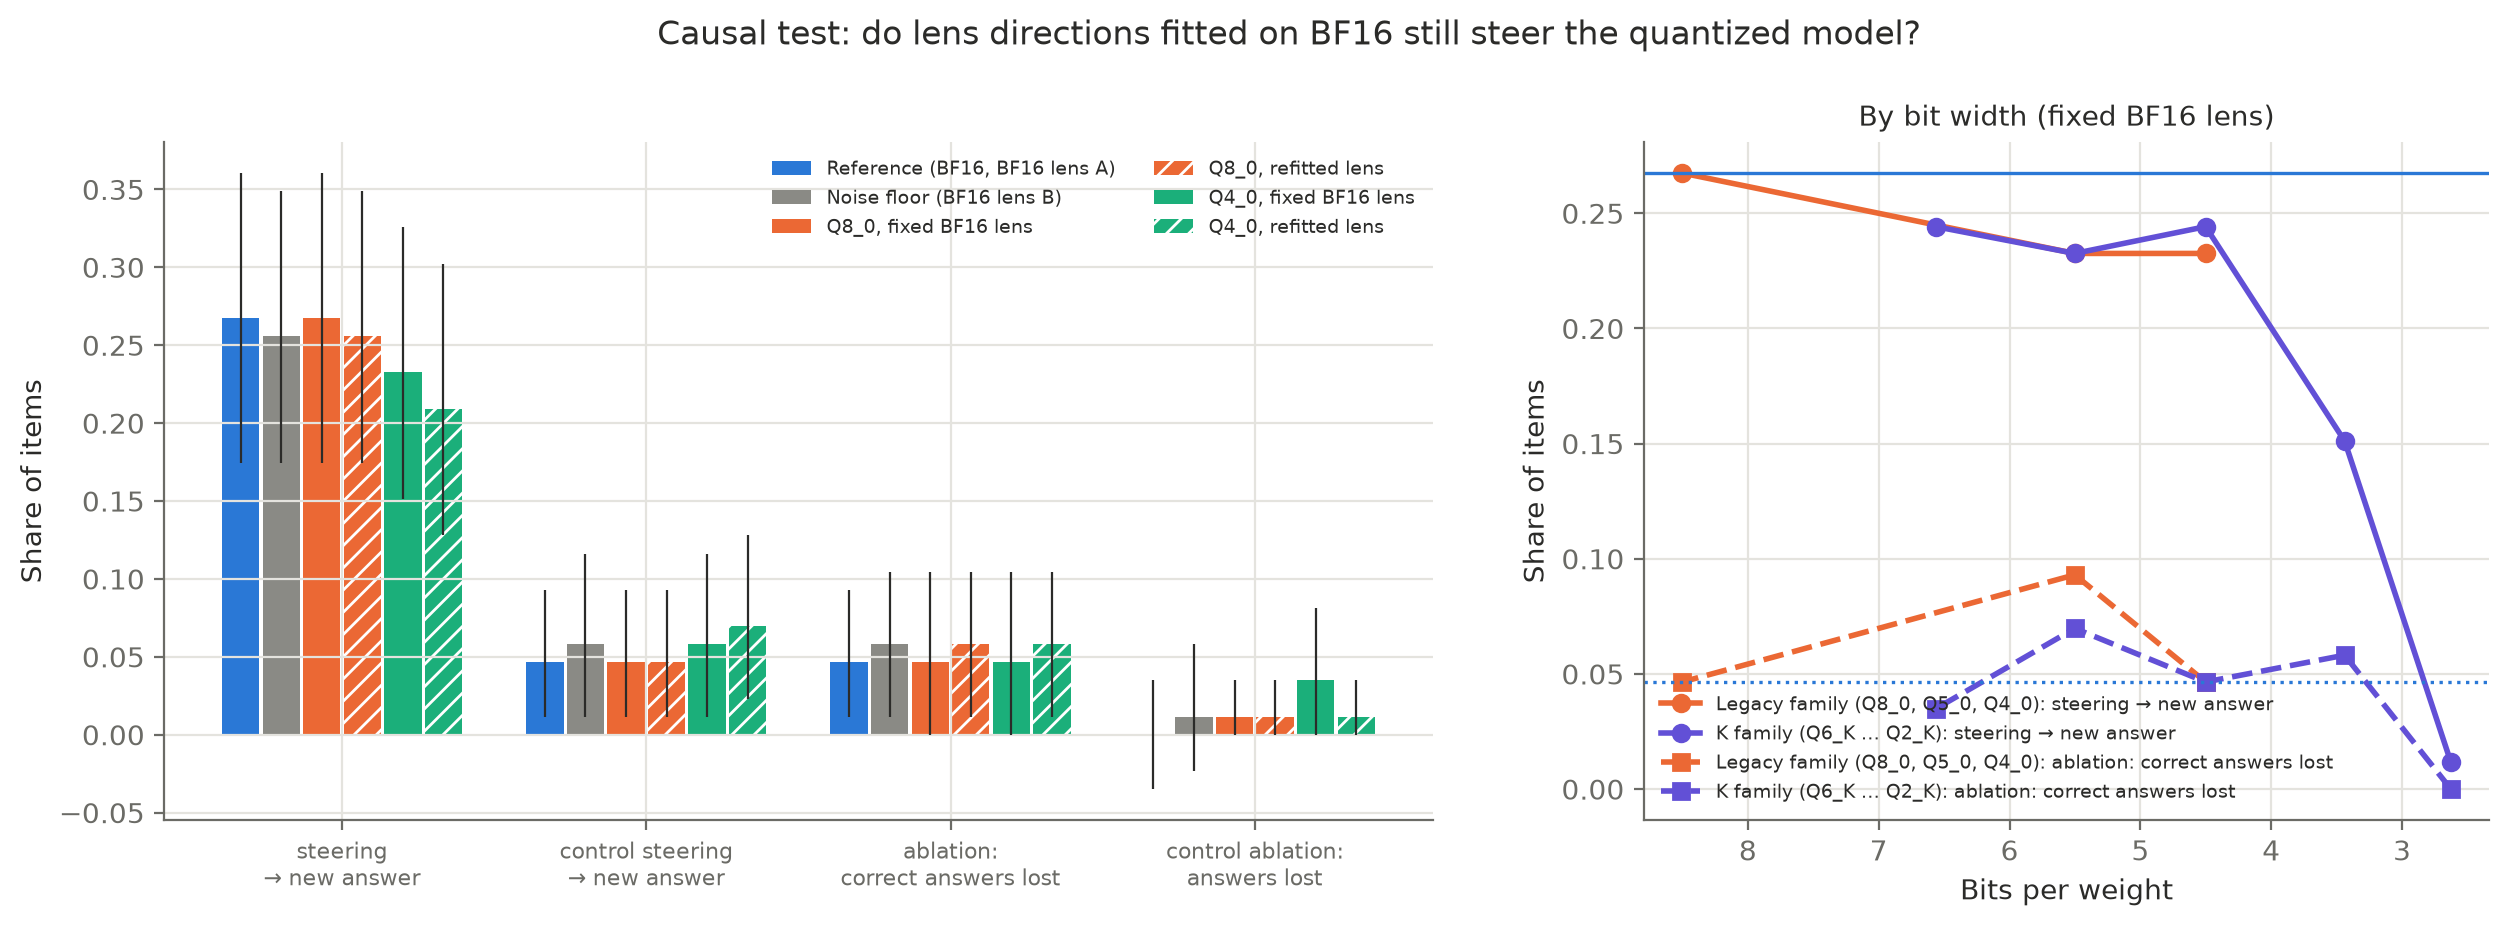

In [13]:
iv = pd.read_csv(T / "interventions_summary.csv")
display(iv[["model", "lens", "baseline_accuracy", "steer_success", "steer_success_vs_ref",
            "steer_success_vs_ref_ci_lo", "steer_success_vs_ref_ci_hi", "steer_control", "ablate_drop"]])
display(Image(F / "interventions.png", width=1100))

## 12. Behavior check

In [14]:
beh = pd.read_csv(T / "behavior.csv")
beh[beh.metric == "heldout_ppl"][["model", "value", "vs_ref", "vs_ref_ci_lo", "vs_ref_ci_hi"]].reset_index(drop=True)

,model,value,vs_ref,vs_ref_ci_lo,vs_ref_ci_hi
0,bf16,113.914,1.000,1.000,1.000
1,q8_0,115.839,1.017,0.976,1.072
2,q5_0,149.178,1.310,1.118,1.569
3,q4_0,166.264,1.460,1.081,1.944
4,q6_k,110.707,0.972,0.917,1.031
5,q5_k,111.120,0.975,0.870,1.095
6,q4_k,151.361,1.329,1.130,1.593
7,q3_k,320.650,2.815,2.154,3.686
8,q2_k,44816.952,393.427,194.250,771.558
9,q4_0-attn,130.452,1.145,0.982,1.339


## 13. Conclusion

- **8 bit** changes nothing measurable.
- **Down to 4 bit** the hidden concepts stay readable, although the readout distribution drifts
  noticeably from ~6 bit on, growing with depth. A refitted lens recovers losses: the space is
  shifted, not destroyed.
- **3 bit** costs concepts, **2 bit** destroys them.
- Steering along the lens directions works causally on the quantized models down to 4 bit as well.

Limitations and reflection: `docs/en/05-results.md`.